# Cardiac MRI Classification (ACDC)

Requires `requirements-mri.txt` and the ACDC data in `data/acdc/`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
from IPython.display import Image, Markdown, display

In [2]:
from huggingface_hub import snapshot_download
from cardiac import config

snapshot_download(
    repo_id="MedOtter/ACDC",
    repo_type="dataset",
    local_dir=str(config.ACDC_DIR),
    ignore_patterns=["*_4d.nii.gz"],
)
print("Downloaded to", config.ACDC_DIR)

c:\Users\LENOVO\anaconda3\envs\crenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 906 files: 100%|██████████| 906/906 [00:06<00:00, 144.99it/s]

Downloaded to D:\cardiac project\data\acdc


In [3]:
from cardiac import config
from cardiac.mri import preprocess

preprocess.main(['--acdc-dir', str(config.ACDC_DIR)])

  training: 100/100
  testing: 50/50
Saved arrays and heart metrics to D:\cardiac project\data\processed


In [4]:
from cardiac.mri import metrics_baseline
metrics_baseline.run()

Logistic Regression  5-fold CV accuracy 0.933
Random Forest        5-fold CV accuracy 0.887
              precision    recall  f1-score   support

         NOR       0.91      1.00      0.95        30
        MINF       0.85      0.93      0.89        30
         DCM       0.93      0.83      0.88        30
         HCM       1.00      0.93      0.97        30
          RV       1.00      0.97      0.98        30

    accuracy                           0.93       150
   macro avg       0.94      0.93      0.93       150
weighted avg       0.94      0.93      0.93       150



{'n_patients': 150,
 'features': ['EDV_LV',
  'ESV_LV',
  'EF_LV',
  'EDV_RV',
  'ESV_RV',
  'EF_RV',
  'MYO_MASS_ED',
  'MYO_MASS_ES',
  'EDV_LV_index',
  'EDV_RV_index',
  'MYO_MASS_index',
  'RV_LV_ratio'],
 'cv_accuracy': {'Logistic Regression': 0.9333333333333333,
  'Random Forest': 0.8866666666666667},
 'best': 'Logistic Regression'}

Device cuda | train 80 | val 20 | test 50
Epoch   1/100 | train 1.642/0.188 | val 1.647/0.150 | 4.0s
Epoch   2/100 | train 1.597/0.212 | val 1.668/0.150 | 1.8s
Epoch   3/100 | train 1.597/0.287 | val 1.641/0.150 | 1.8s
Epoch   4/100 | train 1.558/0.300 | val 1.690/0.200 | 1.9s
Epoch   5/100 | train 1.542/0.325 | val 1.660/0.200 | 2.0s
Epoch   6/100 | train 1.595/0.300 | val 1.625/0.200 | 1.9s
Epoch   7/100 | train 1.475/0.425 | val 1.797/0.200 | 1.9s
Epoch   8/100 | train 1.553/0.362 | val 1.648/0.150 | 1.8s
Epoch   9/100 | train 1.496/0.388 | val 1.954/0.200 | 1.9s
Epoch  10/100 | train 1.453/0.412 | val 1.579/0.150 | 1.9s
Epoch  11/100 | train 1.485/0.375 | val 2.432/0.200 | 1.9s
Epoch  12/100 | train 1.444/0.362 | val 1.808/0.200 | 1.9s
Epoch  13/100 | train 1.454/0.412 | val 2.213/0.200 | 2.0s
Epoch  14/100 | train 1.393/0.438 | val 1.782/0.350 | 2.0s
Epoch  15/100 | train 1.396/0.463 | val 1.868/0.200 | 1.9s
Epoch  16/100 | train 1.416/0.425 | val 1.658/0.300 | 2.0s
Epoch  17/100 

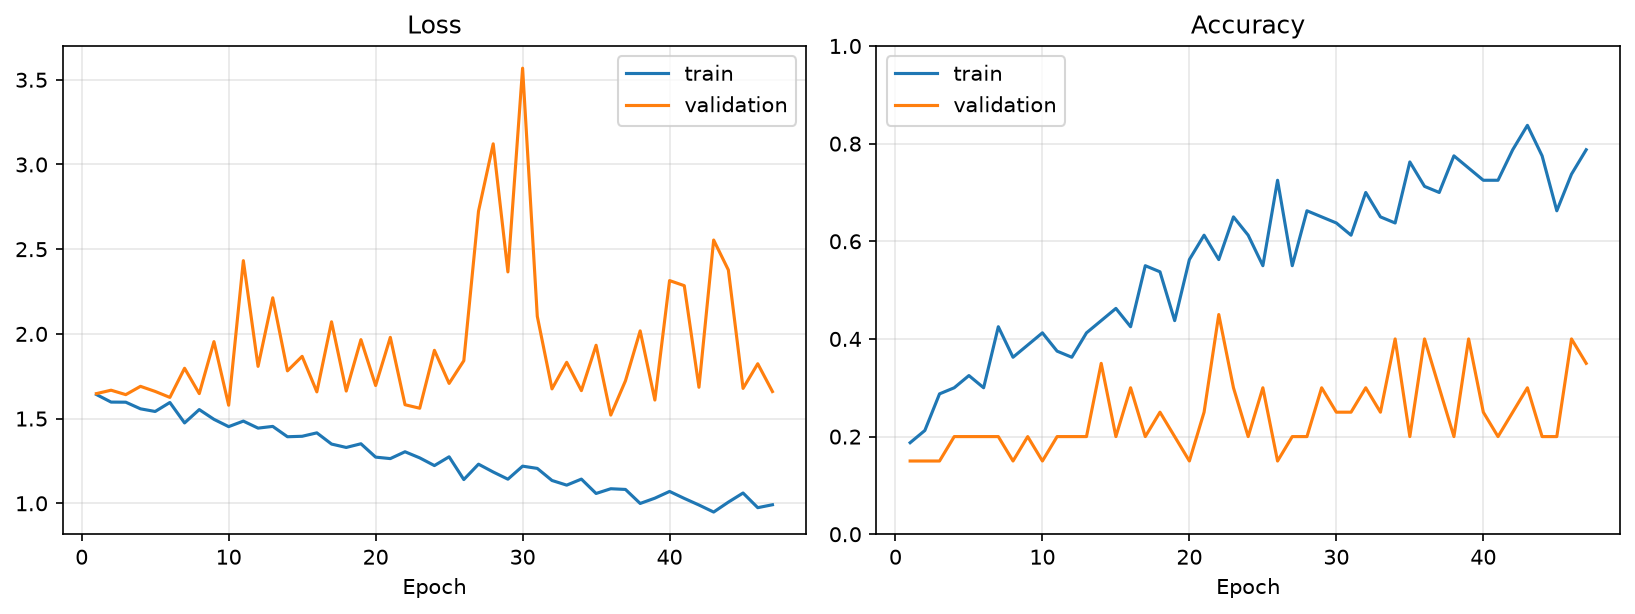

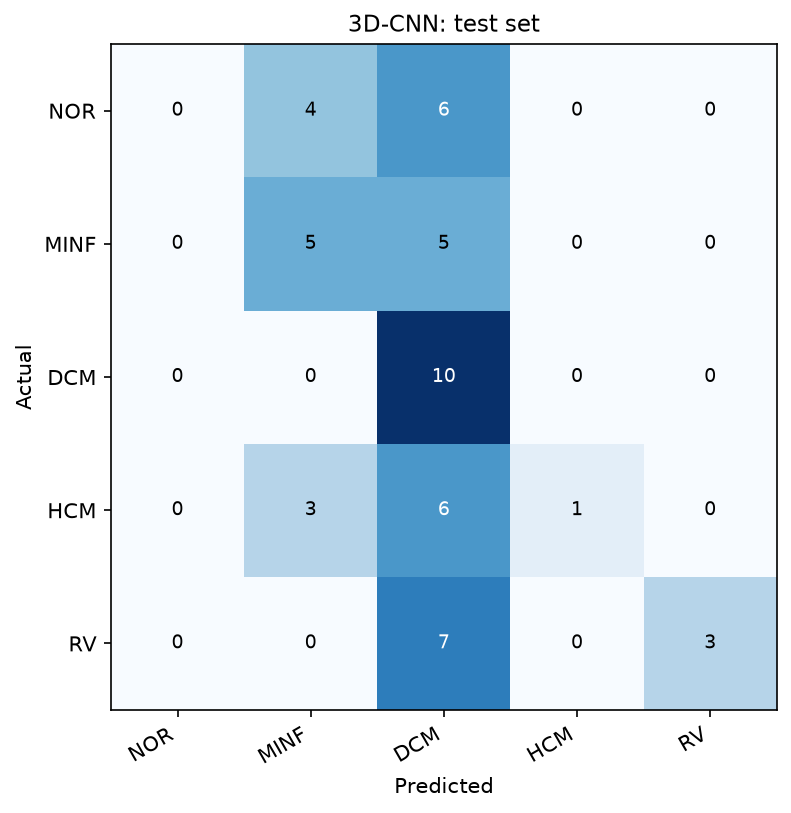

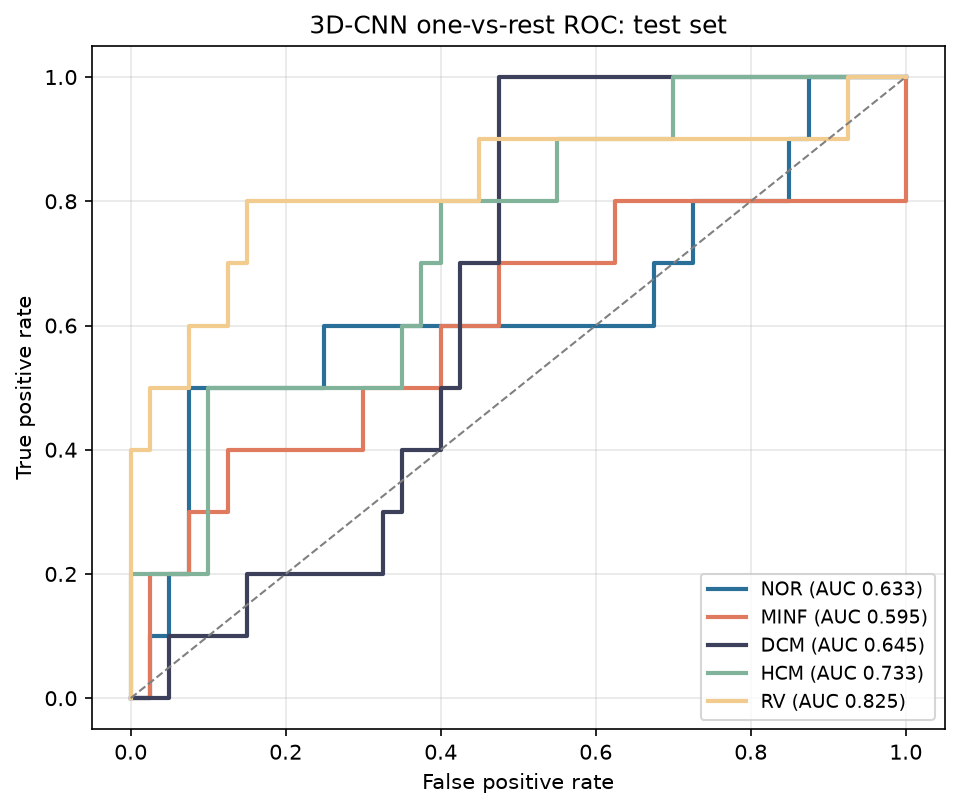

In [5]:
from cardiac.mri import train as mri_train

summary = mri_train.train(epochs=100, batch_size=8)
for f in ['mri_training_curves', 'mri_confusion', 'mri_roc']:
    p = config.FIGURES_DIR / f'{f}.png'
    if p.exists():
        display(Image(filename=str(p)))